# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Question.** An agricultural extension officer wants to compare rainfall regimes across Kampala, Gulu and Mbarara and advise farmers which crops suit which months.

**Approach.** Model each region and each crop with classes, classify every month, correct the flawed `math.cos` similarity method, compare regions with three similarity/distance measures, detect rainy seasons with `scipy.signal.find_peaks`, and finish with a planting advisory.

**Reusable code** lives in `src/rainfall_model.py` (`Region`, `CropRule`, `cosine_similarity`, `pearson_correlation`, `euclidean_distance`, `pairwise_matrix`). Tests are in `tests/test_project4.py`.

**Data.** The monthly rainfall below is *illustrative* (given in the assignment), not measured. Conclusions about real places are therefore tentative; Task 5 and the Findings discuss where the data disagree with known climate.

**Units.** Rainfall in mm per month; months Jan-Dec.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import cosine as scipy_cosine

from src.rainfall_model import (
    MONTHS, CropRule, Region,
    cosine_similarity, euclidean_distance, pairwise_matrix, pearson_correlation,
)

SEED = 2026
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.3f}".format

## Task 1. `Region`: rainfall summary

In [2]:
regions = [
    Region("Kampala", [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130]),
    Region("Gulu",    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15]),
    Region("Mbarara", [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90]),
]
by_name = {r.name: r for r in regions}

summary = pd.DataFrame({
    r.name: {
        "annual total (mm)": r.annual_total,
        "monthly mean (mm)": r.mean,
        "wettest month": r.wettest_month,
        "driest month": r.driest_month,
        "CV of monthly rainfall": r.cv,
    } for r in regions
}).T
display(summary)
print(regions)

,annual total (mm),monthly mean (mm),wettest month,driest month,CV of monthly rainfall
Kampala,"1,600.000",133.333,May,Sep,0.388
Gulu,"1,388.000",115.667,Aug,Jan,0.642
Mbarara,"1,040.000",86.667,Apr,Jul,0.444


[Region('Kampala', annual=1,600 mm), Region('Gulu', annual=1,388 mm), Region('Mbarara', annual=1,040 mm)]


The CV here measures how *unevenly* rain is spread across the 12 months (seasonality), not year-to-year reliability. Gulu's high CV reflects a near-dry January-February against a very wet August.

## Task 2. `CropRule`: crop thresholds and monthly classification

A `CropRule` holds a suitable monthly rainfall range. Below it the month is a **drought risk**, above it a **waterlogging risk**.

| Crop | Seasonal water need | Season length used | Monthly range (mm) | Source |
|---|---|---|---|---|
| Maize | 500-800 mm | 4 months (assumed) | 125-200 | FAO Land & Water, *Maize* crop information page (www.fao.org/land-water/databases-and-software/crop-information/maize) |
| Beans | 300-500 mm | 3 months (FAO gives 60-120 days) | 100-170 | FAO Land & Water, *Bean* crop information page (www.fao.org/land-water/databases-and-software/crop-information/bean) |
| Coffee (Robusta) | about 1,100-1,200 mm/year best yields in a central-Uganda field study | perennial | 80-180 | *Biophysical Constraints to Robusta Coffee Productivity in Low, Moderate, and High Rainfall Areas*, International Journal of Agronomy (2024) |

**How the monthly ranges were derived.** For maize and beans, the FAO seasonal total is divided by the season length (500/4 to 800/4 = 125-200; 300/3 to 500/3 = 100-167, rounded to 170). The 4-month maize season is my assumption; FAO says the season varies with variety, so check it. For coffee, 1,100-1,200 mm/year is about 92-100 mm/month on average; the 80-180 mm band around it is **my judgement**, not a published figure. These are screening thresholds, not agronomic prescriptions; they ignore temperature, soil, evapotranspiration and rainfall within the month. Please verify each source and cite it properly (authors, year, URL) in your README.

In [3]:
rules = [
    CropRule("maize",  125, 200, season_months=4,
             source="FAO Land & Water, Maize page: 500-800 mm per season / 4-month season (assumed)"),
    CropRule("beans",  100, 170, season_months=3,
             source="FAO Land & Water, Bean page: 300-500 mm per 60-120 day crop / 3 months"),
    CropRule("coffee",  80, 180, season_months=None,
             source="Int. J. Agronomy (2024) Robusta rainfall thresholds; band around ~92-100 mm/month is assumed"),
]

for rule in rules:
    table = pd.DataFrame({r.name: rule.classify_region(r) for r in regions}, index=MONTHS).T
    print(f"\n{rule.crop.upper()}  ({rule.low:g}-{rule.high:g} mm/month)")
    display(table)

counts = pd.DataFrame({
    rule.crop: {r.name: rule.classify_region(r).count(f"Good for {rule.crop}") for r in regions}
    for rule in rules
})
print("Number of good months per crop and region (out of 12):")
display(counts)


MAIZE  (125-200 mm/month)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,Drought risk,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Drought risk,Drought risk,Drought risk,Drought risk,Drought risk,Good for maize
Gulu,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Good for maize,Drought risk,Drought risk
Mbarara,Drought risk,Drought risk,Drought risk,Good for maize,Drought risk,Drought risk,Drought risk,Drought risk,Drought risk,Good for maize,Drought risk,Drought risk



BEANS  (100-170 mm/month)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,Good for beans,Good for beans,Waterlogging risk,Waterlogging risk,Waterlogging risk,Waterlogging risk,Drought risk,Drought risk,Drought risk,Good for beans,Good for beans,Good for beans
Gulu,Drought risk,Drought risk,Drought risk,Good for beans,Waterlogging risk,Good for beans,Good for beans,Waterlogging risk,Waterlogging risk,Good for beans,Drought risk,Drought risk
Mbarara,Drought risk,Drought risk,Good for beans,Good for beans,Drought risk,Drought risk,Drought risk,Drought risk,Good for beans,Good for beans,Good for beans,Drought risk



COFFEE  (80-180 mm/month)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,Good for coffee,Good for coffee,Good for coffee,Waterlogging risk,Waterlogging risk,Good for coffee,Good for coffee,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee
Gulu,Drought risk,Drought risk,Drought risk,Good for coffee,Waterlogging risk,Good for coffee,Good for coffee,Waterlogging risk,Good for coffee,Good for coffee,Drought risk,Drought risk
Mbarara,Drought risk,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Drought risk,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee,Good for coffee


Number of good months per crop and region (out of 12):


,maize,beans,coffee
Kampala,5,5,8
Gulu,6,4,5
Mbarara,2,5,8


## Task 3. Correcting the cosine-similarity method

**What was wrong.** `math.cos(x)` returns the cosine of a *single angle x given in radians*. It takes a scalar, so it cannot compare two rainfall vectors at all. Applied to a rainfall value it returns an arbitrary number between -1 and 1 that has nothing to do with similarity.

**Correct definition.** The cosine similarity of vectors a and b is the cosine of the angle between them:

$$\cos\theta = \frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

In [4]:
# The flawed idea: math.cos works on one angle in radians, not on vectors.
print("math.cos(120) =", round(math.cos(120), 4), " <- 120 is read as 120 radians, so this is meaningless")
try:
    math.cos(regions[0].rainfall)
except TypeError as e:
    print("math.cos(vector) fails:", e)

# The correct implementation, verified against SciPy (scipy returns the DISTANCE 1 - cos(theta)).
for i in range(3):
    for j in range(i + 1, 3):
        mine = cosine_similarity(regions[i].rainfall, regions[j].rainfall)
        ref = 1 - scipy_cosine(regions[i].rainfall, regions[j].rainfall)
        assert np.isclose(mine, ref), "mismatch with SciPy"
        print(f"{regions[i].name:8s} vs {regions[j].name:8s}: mine = {mine:.6f}   scipy = {ref:.6f}")
print("All pairs match SciPy.")

math.cos(120) = 0.8142  <- 120 is read as 120 radians, so this is meaningless
math.cos(vector) fails: only 0-dimensional arrays can be converted to Python scalars
Kampala  vs Gulu    : mine = 0.786609   scipy = 0.786609
Kampala  vs Mbarara : mine = 0.891250   scipy = 0.891250
Gulu     vs Mbarara : mine = 0.748678   scipy = 0.748678
All pairs match SciPy.


## Task 4. Similarity and distance matrices

Three measures between every pair of regions: cosine similarity, Pearson correlation (cosine of the mean-centred vectors) and Euclidean distance (mm, in 12-dimensional rainfall space).

In [5]:
names = [r.name for r in regions]
matrices = {
    "Cosine similarity": pairwise_matrix(regions, cosine_similarity),
    "Pearson correlation": pairwise_matrix(regions, pearson_correlation),
    "Euclidean distance (mm)": pairwise_matrix(regions, euclidean_distance),
}
for title, m in matrices.items():
    print(title)
    display(pd.DataFrame(m, index=names, columns=names))

# Why cosine similarity can call a much wetter region "similar":
k = regions[0].rainfall
print("Kampala vs 3 x Kampala (three times wetter, identical shape):")
print(f"  cosine similarity  = {cosine_similarity(k, 3 * k):.3f}")
print(f"  Pearson correlation = {pearson_correlation(k, 3 * k):.3f}")
print(f"  Euclidean distance = {euclidean_distance(k, 3 * k):,.0f} mm")

Cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


Kampala vs 3 x Kampala (three times wetter, identical shape):
  cosine similarity  = 1.000
  Pearson correlation = 1.000
  Euclidean distance = 985 mm


**Why cosine similarity can rate regions as "similar" when one is much wetter.** Cosine similarity depends only on the *direction* of the vectors (the shape of the monthly profile), not their length (total amount). Multiplying a region's rainfall by any positive constant leaves it unchanged, as the 3 × Kampala example shows. Because all rainfall values are non-negative, the vectors also sit in the same positive region of space, so cosine similarity is high (about 0.75-0.89) even for regions whose months are barely correlated: Pearson, which removes each region's mean, is near zero for most pairs. Use cosine for "same shape", Pearson for "same up-and-down pattern across the year", and Euclidean distance when the amounts matter.

## Task 5. Rainy seasons with `scipy.signal.find_peaks`

The year is circular (December rains continue into January), so the series is tiled three times and only peaks in the middle copy are kept. A peak counts as a separate rainy season only if its **prominence** is at least 25% of the region's wettest month, which filters out minor wiggles. Because that cut-off is a judgement call, the sensitivity table below shows how the answer changes with it.

In [6]:
peak_table = pd.DataFrame({
    r.name: {
        "rainy-season peaks": ", ".join(MONTHS[i] for i in r.peaks()),
        "classification (25%)": r.modality(0.25),
    } for r in regions
}).T
display(peak_table)

cutoffs = [0.05, 0.10, 0.15, 0.25, 0.35]
sens = pd.DataFrame({r.name: [r.modality(c) for c in cutoffs] for r in regions},
                    index=[f"{int(c*100)}%" for c in cutoffs])
sens.index.name = "min prominence"
print("Sensitivity of the classification to the prominence cut-off:")
display(sens)

,rainy-season peaks,classification (25%)
Kampala,May,unimodal
Gulu,Aug,unimodal
Mbarara,"Apr, Oct",bimodal


Sensitivity of the classification to the prominence cut-off:


,Kampala,Gulu,Mbarara
min prominence,,,
5%,unimodal,bimodal,bimodal
10%,unimodal,bimodal,bimodal
15%,unimodal,bimodal,bimodal
25%,unimodal,unimodal,bimodal
35%,unimodal,unimodal,bimodal


**Check against Uganda's known climate zones.** Southwestern Uganda (Mbarara) is normally described as bimodal, with rains around March-May and September-November, and the data agree (peaks in April and October). Northern Uganda (Gulu) is commonly described as having one long rainy season from about April to October; at the 25% cut-off the data agree (unimodal), but at 15% or lower a May and an August peak separate, so the verdict depends on the threshold. Central Uganda around Kampala is normally described as bimodal (March-May and September-November), but this illustrative data classify it as unimodal at *every* cut-off: its October-December rise (100-130 mm) is too weak to form a separate peak. That is a disagreement between the illustrative data and the real climate, not evidence that Kampala is unimodal. Verify these climate-zone descriptions against a cited source (for example UNMA or Uganda climate literature) in your README.

## Task 6. Visualisation

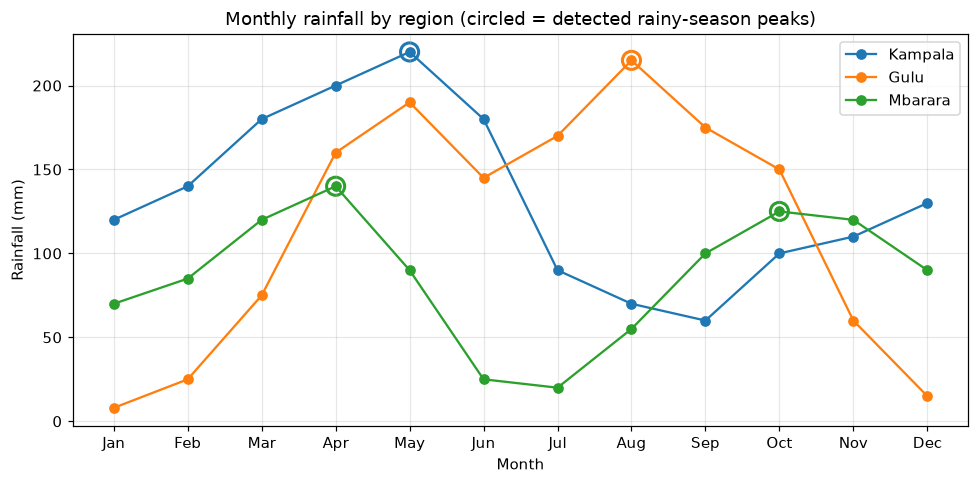

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in regions:
    line, = ax.plot(MONTHS, r.rainfall, marker="o", label=r.name)
    pk = r.peaks()
    ax.scatter([MONTHS[i] for i in pk], r.rainfall[pk], s=140, facecolors="none",
               edgecolors=line.get_color(), linewidths=2)
ax.set(title="Monthly rainfall by region (circled = detected rainy-season peaks)",
       xlabel="Month", ylabel="Rainfall (mm)")
ax.legend(); plt.tight_layout(); plt.show()

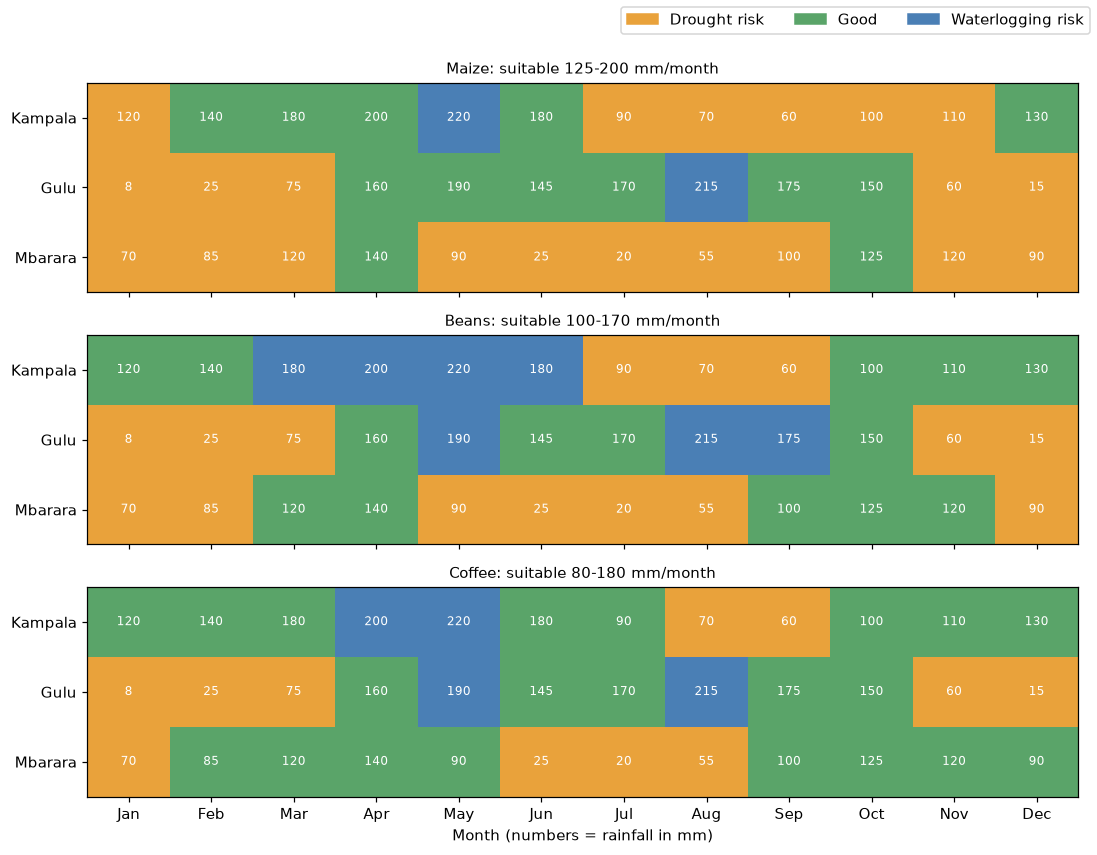

In [8]:
cmap = ListedColormap(["#e9a23b", "#5aa469", "#4a7fb5"])   # drought, good, waterlogging
fig, axes = plt.subplots(len(rules), 1, figsize=(10, 2.6 * len(rules)), sharex=True)
for ax, rule in zip(axes, rules):
    codes = np.array([rule.codes(r) for r in regions])
    ax.imshow(codes, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for i, r in enumerate(regions):
        for j in range(12):
            ax.text(j, i, f"{r.rainfall[j]:.0f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{rule.crop.capitalize()}: suitable {rule.low:g}-{rule.high:g} mm/month", fontsize=10)
    ax.grid(False)
axes[-1].set_xticks(range(12), MONTHS)
axes[-1].set_xlabel("Month (numbers = rainfall in mm)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#e9a23b", "#5aa469", "#4a7fb5"]]
fig.legend(handles, ["Drought risk", "Good", "Waterlogging risk"], loc="upper right", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

## Task 7. Advisory note for farmers in Gulu

The planting window comes from `CropRule.planting_window`, which scans every start month (wrapping past December) and scores the share of the crop's season months that are classed "good".

In [9]:
gulu = by_name["Gulu"]
for rule in rules:
    w = rule.planting_window(gulu)
    print(f"{rule.crop:7s}", "perennial (no planting window)" if w is None else f"best start {w[0]}, {w[1]:.0%} of season months good")

maize   best start Apr, 100% of season months good
beans   best start Apr, 67% of season months good
coffee  perennial (no planting window)


### Advisory note: farmers in Gulu

**Plant maize in April.** On the given rainfall data, April to July (160, 190, 145 and 170 mm) all fall inside the 125-200 mm range maize needs, so a four-month crop started in April has rain in every month of its season. This is the strongest window in the region, with 100% of season months classed good.

**Beans are a weaker choice.** Even the best three-month start, also April, has only two good months out of three, because May (190 mm) is above the 170 mm waterlogging limit. If you grow beans, use well-drained fields.

**Avoid planting from November to March.** Rainfall is below 100 mm in all five of these months (60 mm in November, 8 mm in January), which is a drought risk for maize and beans.

**Coffee** has only five good months in the year here, with dry spells in November to March and heavy rain in May and August, so plan for mulching and water management.

*Based on illustrative data and screening thresholds; check local forecasts.*

## Extension (partial): year-to-year variability

**Important: this uses *synthetic* data, not real rainfall.** Real NASA POWER or UNMA records were not available while building this notebook, so I simulate 15 years around the illustrative Gulu means with a seeded gamma distribution (monthly CV of 0.30 assumed). The numbers show the *method*; they do not describe Gulu's real variability. To earn the full extension, replace `rain_years` with a real (years × 12) array from a cited source and rerun.

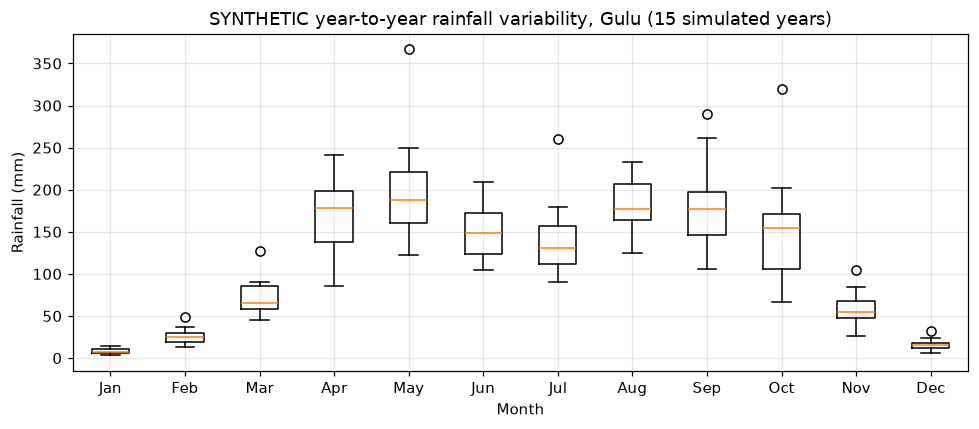

Share of simulated years in which each month is 'good for maize':


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
P(good for maize),0.000,0.000,0.067,0.667,0.533,0.600,0.467,0.667,0.600,0.533,0.000,0.000


In [10]:
rng = np.random.default_rng(SEED)
N_YEARS, CV_MONTH = 15, 0.30
shape = 1 / CV_MONTH ** 2
rain_years = rng.gamma(shape, gulu.rainfall / shape, size=(N_YEARS, 12))   # (years, 12), mm

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(rain_years, tick_labels=MONTHS)
ax.set(title="SYNTHETIC year-to-year rainfall variability, Gulu (15 simulated years)",
       xlabel="Month", ylabel="Rainfall (mm)")
plt.tight_layout(); plt.show()

maize = rules[0]
p_good = np.array([[maize.code(x) == 0 for x in yr] for yr in rain_years]).mean(axis=0)
print("Share of simulated years in which each month is 'good for maize':")
display(pd.DataFrame({"P(good for maize)": p_good}, index=MONTHS).T)

## Findings & Limitations

**Crop suitability.** Gulu is the only region with a clean maize window (April to July, all four months in range). Mbarara has just two good maize months (April and October), so maize there is a high-risk choice on this data, while beans suit its September to November rains well. Kampala and Mbarara have eight good coffee months each; Gulu has five.

**Similarity.** Cosine similarity is high for every pair (0.75 to 0.89), yet Pearson correlation is near zero (-0.17 to 0.21). The regions share the property of having positive rainfall but not the timing of their wet months, so cosine alone would wrongly suggest they follow the same calendar. Euclidean distance (250 to 315 mm) shows that amounts differ as well. Which measure to use depends on whether shape, timing or amount matters to the decision.

**Seasonality.** Mbarara is bimodal at every cut-off tested. Gulu is unimodal at a 25% prominence cut-off but bimodal at 15% or lower, so its classification is threshold-dependent. Kampala is unimodal at every cut-off, which contradicts the usual bimodal description of central Uganda and points to a weakness of the illustrative data.

**Limitations.** The rainfall is a single illustrative year, so year-to-year risk is unknown; the extension simulates variability, but synthetically. Crop ranges are screening thresholds built from FAO seasonal totals and an assumed season length, ignoring temperature, soil, evapotranspiration and rain distribution within a month. The 25% peak cut-off is a judgement call. All conclusions about real places should be re-tested with measured data.